
## 1. Setup and Load Dataset

This section imports the required libraries and loads the finalized `projects_clean.csv` dataset directly from the Origin GitHub repository.

The dataset contains 103 graduation projects from six academic departments, organized into seven columns.

Column names and department labels are standardized in memory to ensure consistent analysis without modifying the original CSV file.


In [1]:

# ============================================================
# 1. SETUP AND LOAD DATASET
# ============================================================

import re
import json
import shutil
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Load the approved CSV from GitHub
csv_url = (
    "https://raw.githubusercontent.com/"
    "esrrahafase-crypto/Origin/main/"
    "data/processed/projects_clean.csv"
)

original_df = pd.read_csv(
    csv_url,
    encoding="utf-8-sig",
    keep_default_na=False
)

# Create a separate copy for analysis
eda_df = original_df.copy()

# Standardize column names
eda_df.columns = (
    eda_df.columns.str.strip().str.lower()
)

# Standardize department labels
department_mapping = {
    "computer science": "Computer Science",
    "artificial intelligence": "Artificial Intelligence",
    "information systems": "Information Systems",
    "data science and analysis": "Data Science and Analysis",
    "information technology": "Information Technology",
    "cybersecurity": "Cybersecurity"
}

eda_df["department"] = (
    eda_df["department"]
    .astype(str)
    .str.strip()
    .map(
        lambda value: department_mapping.get(
            value.lower(), value
        )
    )
)

eda_df["source_page"] = pd.to_numeric(
    eda_df["source_page"],
    errors="raise"
).astype(int)

print("ORIGIN | EXPLORATORY DATA ANALYSIS")
print("=" * 55)
print("Dataset loaded successfully!")
print("Shape:", eda_df.shape)
print("Columns:", eda_df.columns.tolist())

display(eda_df.head(3))


ORIGIN | EXPLORATORY DATA ANALYSIS
Dataset loaded successfully!
Shape: (103, 7)
Columns: ['project_id', 'title', 'abstract', 'department', 'year', 'keywords', 'source_page']


,project_id,title,abstract,department,year,keywords,source_page
0,P001,Automatic Plant Watering and Tracking System,Many people struggle with watering their plant...,Computer Science,2024 – 2025,"Moisturem Air humidity, AWTS system, Waterin, ...",5
1,P002,علامة CourseAssist: CLO Performance Assistant ...,The rapid evolution of educational technology ...,Computer Science,2024 – 2025,"Program Learning Outcomes, Course Learning Out...",6
2,P003,واصف Mobile Application for Deaf and Mute indi...,"Our System, Wasif, offers a communication appl...",Computer Science,2024 – 2025,"Arabic Sign Language, Sign Language Gestures i...",7




## 2. Dataset Overview and Quality Assessment

This section examines the dataset structure and verifies its completeness and consistency.

The analysis checks the total number of records, required columns, empty values, duplicate project identifiers, duplicate titles, and department classifications.

These checks confirm that the approved dataset is structurally suitable for further analysis and retrieval experiments.


In [2]:

# ============================================================
# 2. DATASET OVERVIEW AND QUALITY ASSESSMENT
# ============================================================

required_columns = [
    "project_id",
    "title",
    "abstract",
    "keywords",
    "department",
    "year",
    "source_page"
]

expected_counts = {
    "Computer Science": 33,
    "Artificial Intelligence": 12,
    "Information Systems": 23,
    "Data Science and Analysis": 10,
    "Information Technology": 17,
    "Cybersecurity": 8
}

print("DATASET INFORMATION")
print("=" * 55)

print("Total projects:", len(eda_df))
print("Total columns:", len(eda_df.columns))

print("\nMISSING / EMPTY VALUES")

missing_counts = pd.Series({
    col: (
        eda_df[col].isna()
        | eda_df[col].astype(str).str.strip().eq("")
    ).sum()
    for col in required_columns
})

display(
    missing_counts.rename("missing_count").to_frame()
)

print("\nDUPLICATE CHECK")
print(
    "Duplicate IDs:",
    eda_df["project_id"].duplicated().sum()
)
print(
    "Duplicate titles:",
    eda_df["title"].duplicated().sum()
)
print(
    "Duplicate source pages:",
    eda_df["source_page"].duplicated().sum()
)

print("\nACADEMIC YEAR")
print(eda_df["year"].value_counts())

# Verify the approved dataset
assert len(eda_df) == 103
assert set(required_columns).issubset(eda_df.columns)
assert eda_df["project_id"].is_unique
assert eda_df["title"].is_unique
assert eda_df["source_page"].is_unique

actual_counts = eda_df["department"].value_counts()

assert actual_counts.to_dict() == expected_counts, (
    "Department distribution does not match."
)

assert missing_counts.drop("keywords").eq(0).all(), (
    "Missing values detected in required fields."
)

print("\nDataset structure validation passed!")


DATASET INFORMATION
Total projects: 103
Total columns: 7

MISSING / EMPTY VALUES


,missing_count
project_id,0
title,0
abstract,0
keywords,0
department,0
year,0
source_page,0



DUPLICATE CHECK
Duplicate IDs: 0
Duplicate titles: 0
Duplicate source pages: 0

ACADEMIC YEAR
year
2024 – 2025    103
Name: count, dtype: int64

Dataset structure validation passed!



## 3. Project Distribution by Department

This section examines the distribution of graduation projects across the six academic departments.

A bar chart is generated to visualize the number of projects within each department and identify differences in dataset coverage.

Understanding department representation is important when interpreting retrieval results and evaluating the diversity of the available project collection.


PROJECT DISTRIBUTION


,number_of_projects
department,
Computer Science,33
Artificial Intelligence,12
Information Systems,23
Data Science and Analysis,10
Information Technology,17
Cybersecurity,8


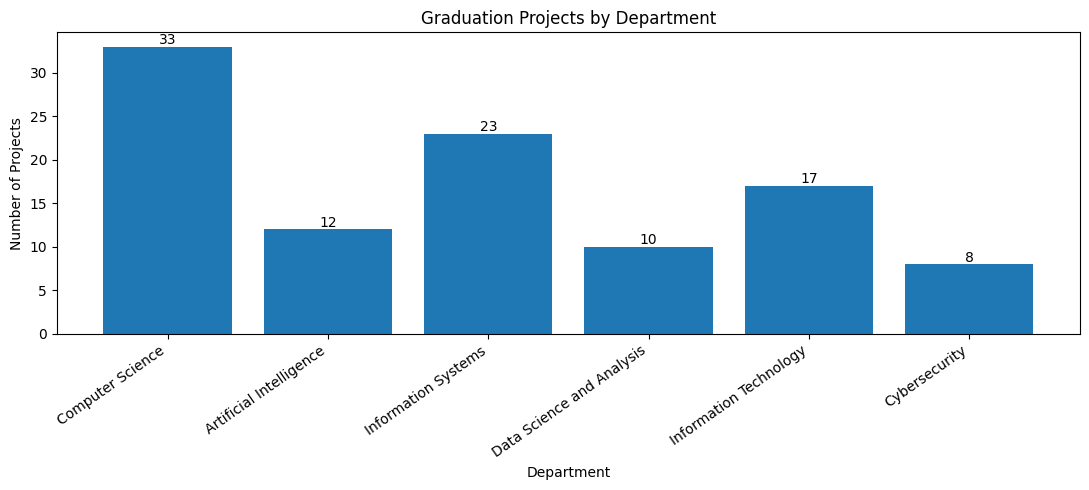

In [3]:

# ============================================================
# 3. PROJECT DISTRIBUTION BY DEPARTMENT
# ============================================================

output_dir = Path("/content/origin_eda_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

department_counts = (
    eda_df["department"]
    .value_counts()
    .reindex(expected_counts.keys())
)

print("PROJECT DISTRIBUTION")
print("=" * 55)

display(
    department_counts.rename(
        "number_of_projects"
    ).to_frame()
)

# Visualize department distribution
plt.figure(figsize=(11, 5))

bars = plt.bar(
    department_counts.index,
    department_counts.values
)

plt.title("Graduation Projects by Department")
plt.xlabel("Department")
plt.ylabel("Number of Projects")

plt.xticks(rotation=35, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    output_dir / "department_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




## 4. Project Title and Abstract Length Analysis

This section analyzes the textual characteristics of project titles and abstracts.

Word counts are calculated to examine text length distributions, identify unusually short or long descriptions, and compare abstract lengths across departments.

These observations help guide text preprocessing decisions and provide context for later semantic retrieval experiments.


TEXT LENGTH STATISTICS


,title_words,abstract_words
count,103.0,103.00
mean,6.1,171.33
std,4.1,49.83
min,1.0,61.00
25%,3.0,145.50
50%,5.0,168.00
75%,9.0,205.50
max,16.0,277.00



ABSTRACT LENGTH BY DEPARTMENT


,count,min,median,mean,max
department,,,,,
Computer Science,33,63,156.0,158.48,277
Artificial Intelligence,12,61,176.0,167.25,224
Information Systems,23,111,168.0,180.52,277
Data Science and Analysis,10,156,181.0,186.00,241
Information Technology,17,82,155.0,172.59,257
Cybersecurity,8,153,177.0,183.00,249


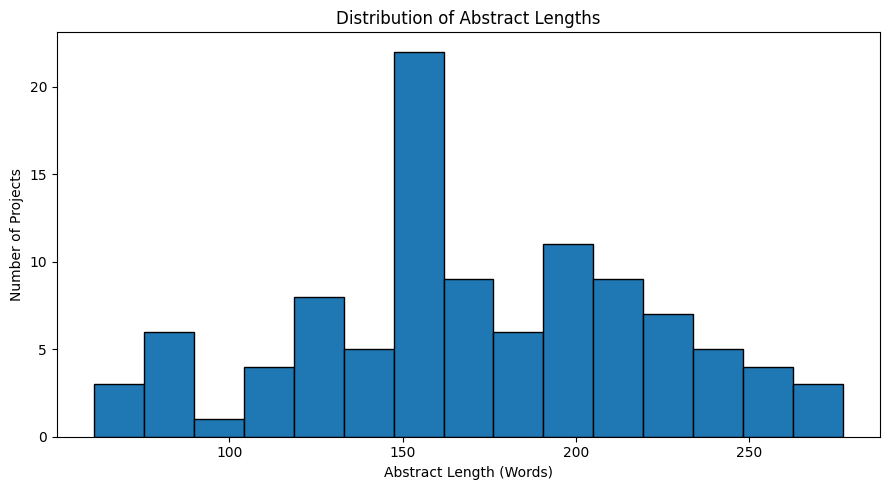


SHORTEST ABSTRACTS


,project_id,title,department,abstract_words
40,P041,PNU ChatBot,Artificial Intelligence,61
15,P016,PulseXPert-Health Disorder Detection,Computer Science,63
26,P027,ParkPro,Computer Science,74
25,P026,Potato Guard,Computer Science,76
23,P024,Crime analysis and prediction,Computer Science,79



LONGEST ABSTRACTS


,project_id,title,department,abstract_words
5,P006,YUSUR,Computer Science,277
51,P052,نبر Nabrah,Information Systems,277
63,P064,Be Prepared Game,Information Systems,268
54,P055,Tabayn (تبیّن),Information Systems,260
81,P082,Predicting Diabetes Patients Based On Machine ...,Information Technology,257


In [4]:

# ============================================================
# 4. TEXT LENGTH ANALYSIS
# ============================================================

eda_df["title_words"] = (
    eda_df["title"].astype(str).str.split().str.len()
)

eda_df["abstract_words"] = (
    eda_df["abstract"].astype(str).str.split().str.len()
)

print("TEXT LENGTH STATISTICS")
print("=" * 55)

display(
    eda_df[
        ["title_words", "abstract_words"]
    ].describe().round(2)
)

print("\nABSTRACT LENGTH BY DEPARTMENT")

abstract_stats = (
    eda_df.groupby("department")["abstract_words"]
    .agg(["count", "min", "median", "mean", "max"])
    .reindex(expected_counts.keys())
    .round(2)
)

display(abstract_stats)

# Visualize abstract lengths
plt.figure(figsize=(9, 5))

plt.hist(
    eda_df["abstract_words"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Abstract Lengths")
plt.xlabel("Abstract Length (Words)")
plt.ylabel("Number of Projects")

plt.tight_layout()

plt.savefig(
    output_dir / "abstract_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSHORTEST ABSTRACTS")

display(
    eda_df.nsmallest(
        5, "abstract_words"
    )[
        [
            "project_id",
            "title",
            "department",
            "abstract_words"
        ]
    ]
)

print("\nLONGEST ABSTRACTS")

display(
    eda_df.nlargest(
        5, "abstract_words"
    )[
        [
            "project_id",
            "title",
            "department",
            "abstract_words"
        ]
    ]
)



## 5. Keywords Analysis

This section explores the keywords associated with the graduation projects.

Keywords are separated into individual terms, normalized for case consistency, and counted to identify frequently occurring technical concepts and research topics.

The analysis provides an overview of the terminology represented in the dataset and may inform later lexical and hybrid retrieval experiments.

Keywords that were manually supplemented should be distinguished from those directly extracted from the source document when interpreting the results.


KEYWORDS ANALYSIS
Total projects: 103
Unique normalized keywords: 388

TOP 15 MOST FREQUENT KEYWORDS


,keyword,project_count
0,artificial intelligence,18
1,machine learning,18
2,deep learning,15
3,natural language processing,8
4,convolutional neural network,6
5,mobile application,4
6,arabic language,4
7,accessibility,3
8,arabic sign language,2
9,voice recognition,2


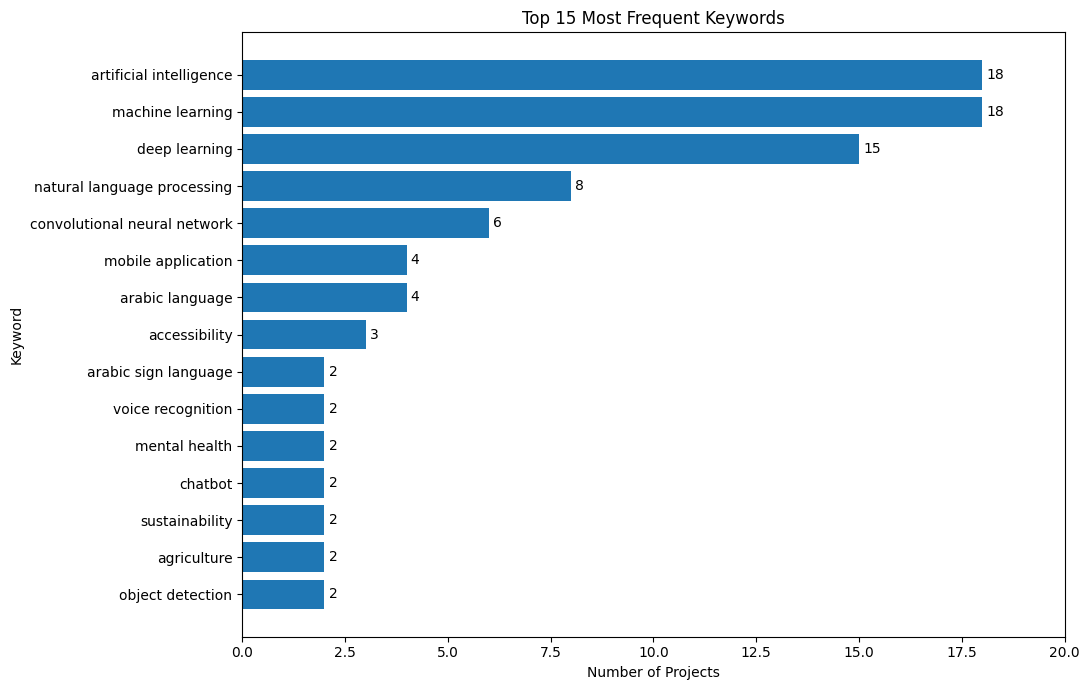


Keyword analysis completed successfully!
Figure saved to: /content/origin_eda_outputs/top_keywords.png


In [7]:

# ============================================================
# 5. KEYWORDS ANALYSIS
# Origin - Exploratory Data Analysis
# ============================================================

import re
from collections import Counter
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Create output directory
output_dir = Path("/content/origin_eda_outputs")
output_dir.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Keyword Normalization
# ------------------------------------------------------------

keyword_aliases = {
    "machine learning (ml)": "machine learning",
    "artificial intelligence (ai)": "artificial intelligence",
    "deep learning (dl)": "deep learning",
    "natural language processing (nlp)": "natural language processing",

    "cnn": "convolutional neural network",
    "cnns": "convolutional neural network",
    "convolutional neural networks": "convolutional neural network",
    "convolutional neural network (cnn)": "convolutional neural network",
    "convolutional neural networks (cnns)": "convolutional neural network"
}


def normalize_keyword(term):
    term = re.sub(
        r"\s+", " ", str(term)
    ).strip().lower()

    term = term.strip(" .,:;!?،؛")

    return keyword_aliases.get(term, term)


# ------------------------------------------------------------
# 2. Extract and Count Keywords
# ------------------------------------------------------------

keyword_counter = Counter()

for keywords in eda_df["keywords"]:

    terms = re.split(r"[,;]", str(keywords))

    normalized_terms = set()

    for term in terms:
        normalized = normalize_keyword(term)

        if normalized:
            normalized_terms.add(normalized)

    # Count each keyword once per project
    keyword_counter.update(normalized_terms)


# ------------------------------------------------------------
# 3. Create Keyword Frequency Table
# ------------------------------------------------------------

keyword_df = pd.DataFrame(
    keyword_counter.most_common(),
    columns=["keyword", "project_count"]
)

print("KEYWORDS ANALYSIS")
print("=" * 55)

print("Total projects:", len(eda_df))
print("Unique normalized keywords:", len(keyword_df))

print("\nTOP 15 MOST FREQUENT KEYWORDS")
display(keyword_df.head(15))


# ------------------------------------------------------------
# 4. Visualize Top 15 Keywords
# ------------------------------------------------------------

top_keywords = keyword_df.head(15).iloc[::-1]

plt.figure(figsize=(11, 7))

bars = plt.barh(
    top_keywords["keyword"],
    top_keywords["project_count"]
)

plt.title("Top 15 Most Frequent Keywords")
plt.xlabel("Number of Projects")
plt.ylabel("Keyword")

# Add frequency labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.1,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center"
    )

plt.xlim(
    0,
    top_keywords["project_count"].max() + 2
)

plt.tight_layout()


# ------------------------------------------------------------
# 5. Save Keyword Visualization
# ------------------------------------------------------------

figure_path = output_dir / "top_keywords.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nKeyword analysis completed successfully!")
print("Figure saved to:", figure_path)


In [8]:

# ============================================================
# 6. SAVE EDA RESULTS
# Origin - Exploratory Data Analysis
# ============================================================

import json
import shutil
from pathlib import Path
from google.colab import files

# ------------------------------------------------------------
# 1. Create Output Directory
# ------------------------------------------------------------

output_dir = Path("/content/origin_eda_outputs")
output_dir.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Save Department Distribution
# ------------------------------------------------------------

department_counts.rename(
    "number_of_projects"
).to_csv(
    output_dir / "department_counts.csv",
    header=True,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 3. Save Abstract Length Statistics
# ------------------------------------------------------------

abstract_stats.to_csv(
    output_dir / "abstract_length_statistics.csv",
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 4. Save Keyword Frequencies
# ------------------------------------------------------------

keyword_df.to_csv(
    output_dir / "keyword_frequencies.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 5. Save Overall EDA Summary
# ------------------------------------------------------------

quality_summary = {
    "total_projects": int(len(eda_df)),
    "total_columns": int(len(original_df.columns)),
    "total_departments": int(
        eda_df["department"].nunique()
    ),
    "missing_values": {
        col: int(
            eda_df[col].astype(str).str.strip().eq("").sum()
        )
        for col in original_df.columns.str.lower()
    },
    "duplicate_project_ids": int(
        eda_df["project_id"].duplicated().sum()
    ),
    "duplicate_titles": int(
        eda_df["title"].duplicated().sum()
    ),
    "average_abstract_words": round(
        float(eda_df["abstract_words"].mean()), 2
    ),
    "minimum_abstract_words": int(
        eda_df["abstract_words"].min()
    ),
    "maximum_abstract_words": int(
        eda_df["abstract_words"].max()
    ),
    "unique_normalized_keywords": int(
        len(keyword_df)
    )
}

with open(
    output_dir / "eda_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        quality_summary,
        file,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 6. Verify Saved Outputs
# ------------------------------------------------------------

expected_files = [
    "department_counts.csv",
    "abstract_length_statistics.csv",
    "keyword_frequencies.csv",
    "eda_summary.json",
    "department_distribution.png",
    "abstract_length_distribution.png",
    "top_keywords.png"
]

print("EDA RESULTS VALIDATION")
print("=" * 55)

for filename in expected_files:
    file_path = output_dir / filename

    assert file_path.is_file(), (
        f"Missing output file: {filename}. "
        "Run the corresponding EDA cell first."
    )

    print("Saved:", filename)


# ------------------------------------------------------------
# 7. Create ZIP Archive
# ------------------------------------------------------------

archive_path = shutil.make_archive(
    "/content/origin_eda_outputs",
    "zip",
    root_dir=output_dir
)

print("\nEDA ANALYSIS COMPLETED SUCCESSFULLY!")
print("=" * 55)

print("Total projects:", len(eda_df))
print("Total departments:", eda_df["department"].nunique())
print("Generated files:", len(expected_files))
print("Archive:", archive_path)


# ------------------------------------------------------------
# 8. Download Results
# ------------------------------------------------------------

files.download(archive_path)


EDA RESULTS VALIDATION
Saved: department_counts.csv
Saved: abstract_length_statistics.csv
Saved: keyword_frequencies.csv
Saved: eda_summary.json
Saved: department_distribution.png
Saved: abstract_length_distribution.png
Saved: top_keywords.png

EDA ANALYSIS COMPLETED SUCCESSFULLY!
Total projects: 103
Total departments: 6
Generated files: 7
Archive: /content/origin_eda_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>